## Experiment 2 — Data Preprocessing Pipeline
**Dataset:** Iris Dataset (Fisher's Classic)  
**Objective:** Prepare raw data for analysis by handling missing values, encoding categorical features, scaling numerical variables, and detecting/removing outliers.  
**Techniques:** Median/mode imputation, one-hot encoding, label encoding, StandardScaler, MinMaxScaler, IQR-based outlier removal.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, MinMaxScaler, LabelEncoder

### 1. Setup & Imports
Load libraries required for data preprocessing: pandas and numpy for data handling, scikit-learn for scaling, and matplotlib/seaborn for visualisation.

In [2]:
df = pd.read_csv("Iris.csv")
print(df.shape[0], df.shape[1])
df.info()

150 6
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    str    
dtypes: float64(4), int64(1), str(1)
memory usage: 9.1 KB


### 2. Load Dataset
Read the raw CSV file and display its shape, data types, and a sample of rows to understand the starting state of the data before any cleaning.

In [3]:
missing = pd.DataFrame({
    "Missing": df.isnull().sum(),
    "Percent": (df.isnull().mean() * 100).round(2)
})
print("Missing values summary:")
print(missing)

Missing values summary:
               Missing  Percent
Id                   0      0.0
SepalLengthCm        0      0.0
SepalWidthCm         0      0.0
PetalLengthCm        0      0.0
PetalWidthCm         0      0.0
Species              0      0.0


### 3. Missing Value Analysis
Detect and quantify missing values in each column. Understanding the missingness pattern guides the choice of imputation strategy (median for numerics, mode for categoricals).

In [4]:
# Drop non-predictive identifier column 'Id'
df_clean = df.drop(columns=["Id"], errors="ignore").copy()
numeric_cols = df_clean.select_dtypes(include=np.number).columns
categorical_cols = df_clean.select_dtypes(exclude=np.number).columns

for col in numeric_cols:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

for col in categorical_cols:
    df_clean[col] = df_clean[col].fillna(df_clean[col].mode()[0])

print("Total missing values after imputation:", df_clean.isnull().sum().sum())

Total missing values after imputation: 0


### 4. Missing Value Imputation
Fill numeric missing values with the column median (robust to outliers) and categorical missing values with the column mode. Verify that no missing values remain after imputation.

In [5]:
for col in categorical_cols:
    print(col, df_clean[col].unique())

df_encoded = pd.get_dummies(df_clean, columns=categorical_cols, drop_first=True)
print("Encoded shape:", df_encoded.shape)
print(df_encoded.head())

demo_col = "Species"
codes = LabelEncoder().fit_transform(df_clean[demo_col].astype(str))
print(pd.DataFrame({demo_col: df_clean[demo_col], "Encoded": codes}).head())

Species <ArrowStringArray>
['Iris-setosa', 'Iris-versicolor', 'Iris-virginica']
Length: 3, dtype: str
Encoded shape: (150, 6)
   SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm  \
0            5.1           3.5            1.4           0.2   
1            4.9           3.0            1.4           0.2   
2            4.7           3.2            1.3           0.2   
3            4.6           3.1            1.5           0.2   
4            5.0           3.6            1.4           0.2   

   Species_Iris-versicolor  Species_Iris-virginica  
0                    False                   False  
1                    False                   False  
2                    False                   False  
3                    False                   False  
4                    False                   False  
       Species  Encoded
0  Iris-setosa        0
1  Iris-setosa        0
2  Iris-setosa        0
3  Iris-setosa        0
4  Iris-setosa        0


### 5. Categorical Encoding
Convert categorical string features to numeric representations. One-hot encoding is applied to nominal features (no intrinsic order); label encoding to ordinal features where the order carries meaning.

In [6]:
std_df = pd.DataFrame(StandardScaler().fit_transform(df_clean[numeric_cols]), columns=numeric_cols)
mm_df = pd.DataFrame(MinMaxScaler().fit_transform(df_clean[numeric_cols]), columns=numeric_cols)

print("Standard Scaler summary:\n", std_df.agg(["mean", "std"]).round(2))
print("MinMax Scaler summary:\n", mm_df.agg(["min", "max"]).round(2))

Standard Scaler summary:
       SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm
mean           -0.0          -0.0            0.0          -0.0
std             1.0           1.0            1.0           1.0
MinMax Scaler summary:
      SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm
min            0.0           0.0            0.0           0.0
max            1.0           1.0            1.0           1.0


### 6. Feature Scaling
Apply StandardScaler (zero mean, unit variance) and MinMaxScaler (range [0, 1]) to numerical columns. Scaling is critical for distance-based algorithms (KNN) and gradient-based optimisers (Logistic Regression).

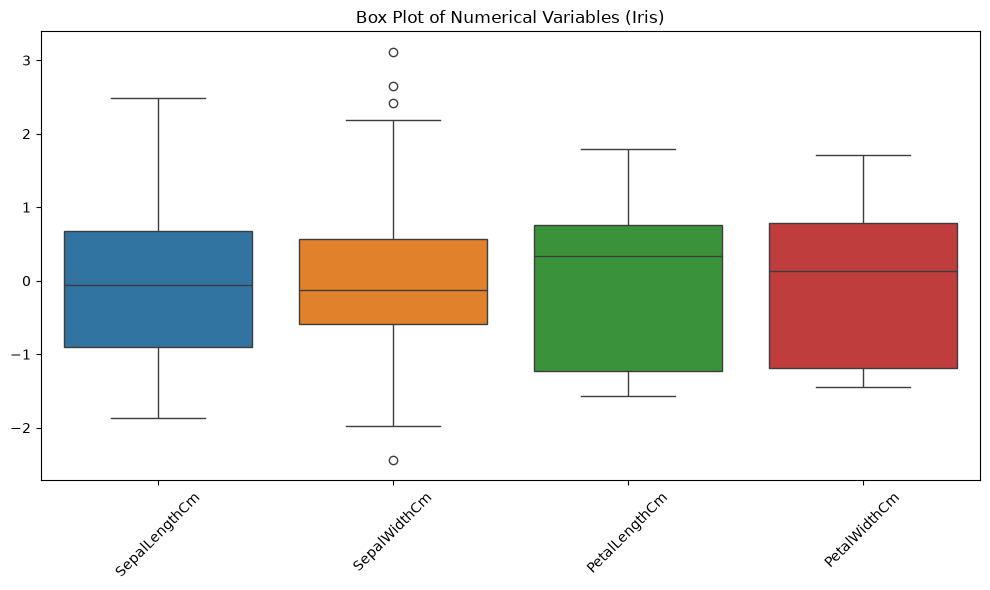

          Column   Q1   Q3  IQR  Lower  Upper  Outliers
0  SepalLengthCm  5.1  6.4  1.3   3.15   8.35         0
1   SepalWidthCm  2.8  3.3  0.5   2.05   4.05         4
2  PetalLengthCm  1.6  5.1  3.5  -3.65  10.35         0
3   PetalWidthCm  0.3  1.8  1.5  -1.95   4.05         0


In [7]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=std_df)
plt.title("Box Plot of Numerical Variables (Iris)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

rows = []
for col in numeric_cols:
    q1, q3 = df_clean[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((df_clean[col] < lo) | (df_clean[col] > hi)).sum()
    rows.append([col, q1, q3, iqr, lo, hi, n_out])

iqr_table = pd.DataFrame(rows, columns=["Column", "Q1", "Q3", "IQR", "Lower", "Upper", "Outliers"])
print(iqr_table)

### 7. Outlier Detection & Removal
Use the Interquartile Range (IQR) method to identify observations that lie beyond 1.5 × IQR from the first and third quartiles. Outliers can distort model coefficients and summary statistics.

In [8]:
outlier_col = "SepalLengthCm"
lo, hi = iqr_table.set_index("Column").loc[outlier_col, ["Lower", "Upper"]]
df_final = df_clean[df_clean[outlier_col].between(lo, hi)].copy()
print(f"Original rows: {len(df_clean)} | After outlier removal on {outlier_col}: {len(df_final)}")

Original rows: 150 | After outlier removal on SepalLengthCm: 150


### 8. Save Preprocessed Dataset
Export the cleaned and transformed DataFrame to CSV so downstream experiments can load a consistent, analysis-ready version of the data.

In [9]:
df_final.to_csv("preprocessed_dataset.csv", index=False)
print("Saved preprocessed dataset to preprocessed_dataset.csv")

Saved preprocessed dataset to preprocessed_dataset.csv
